In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
Animal = pd.DataFrame(pd.read_csv('data/animal_c.csv'))
df = pd.DataFrame(pd.read_csv('data/changes-residential-duration-covid.csv'))

In [46]:

pandemia_casa = df[df['Entity'] == 'Spain'].copy()
pandemia_casa['Day'] = pd.to_datetime(pandemia_casa['Day'])
pandemia_casa_sincols = pandemia_casa.drop(columns='Code')
pandemia_casa_sincols_def = pandemia_casa_sincols.drop(columns='Entity')



In [47]:

pandemia_casa_sincols_def

,Day,Residential
106747,2020-02-17,-1.667
106748,2020-02-18,-1.250
106749,2020-02-19,-1.200
106750,2020-02-20,-1.167
106751,2020-02-21,-1.286
...,...,...
107714,2022-10-11,-0.571
107715,2022-10-12,1.429
107716,2022-10-13,1.571
107717,2022-10-14,1.571


In [48]:
Animal['Time'] = pd.to_datetime(Animal['Time'])
Animal = Animal.set_index('Time')
Animal.loc['2020']

,Animal Crossing
Time,
2020-01-05,4
2020-01-12,4
2020-01-19,4
2020-01-26,6
2020-02-02,7
2020-02-09,6
2020-02-16,11
2020-02-23,13
2020-03-01,12


In [49]:
casa = pandemia_casa_sincols_def.set_index('Day')
casa_2020 = casa.loc['2020']
casa_2020.shape

(319, 1)

In [50]:
casa_semanal = casa_2020.resample('W-SUN', label='left', closed='left').mean()
casa_semanal.head()

,Residential
Day,
2020-02-16,-1.309333
2020-02-23,-1.081714
2020-03-01,-0.428571
2020-03-08,0.367429
2020-03-15,16.469286


In [51]:
juntos = casa_semanal.join(Animal, how='inner')
print(juntos.shape)
juntos.corr()

(46, 2)


,Residential,Animal Crossing
Residential,1.000000,0.890319
Animal Crossing,0.890319,1.000000


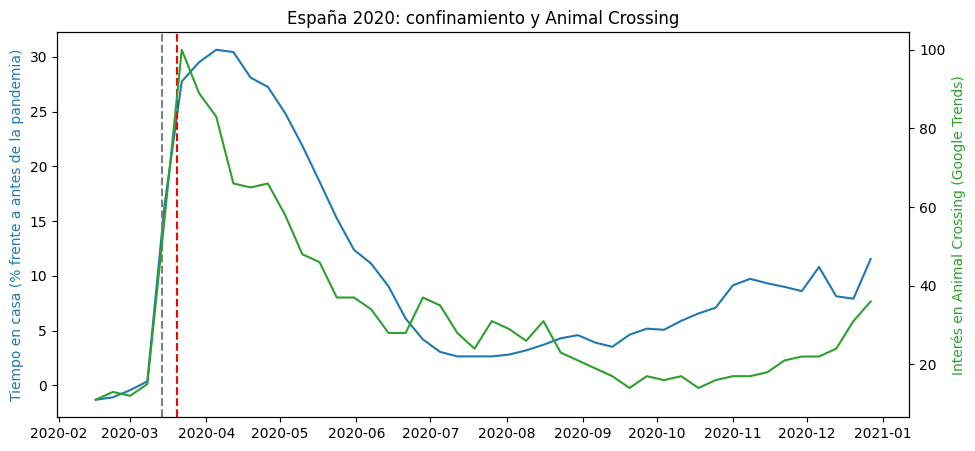

In [52]:
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(juntos.index, juntos['Residential'], color='tab:blue')
ax1.set_ylabel('Tiempo en casa (% frente a antes de la pandemia)', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(juntos.index, juntos['Animal Crossing'], color='tab:green')
ax2.set_ylabel('Interés en Animal Crossing (Google Trends)', color='tab:green')

ax1.axvline(pd.Timestamp('2020-03-14'), color='grey', linestyle='--')  # estado de alarma
ax1.axvline(pd.Timestamp('2020-03-20'), color='red', linestyle='--')   # lanzamiento

plt.title('España 2020: confinamiento y Animal Crossing')
plt.savefig('presentacion/img/01_animal_crossing.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

In [53]:
#LIMPIAR DATASET PISA

pisa_data = pd.DataFrame(pd.read_csv('data/pisa.csv'))
pisa_ue_25 = pd.DataFrame(pd.read_csv('data/PISA_2025_UE.csv'))

In [54]:
pisa_data

,Entity,Code,Year,Reading
0,Albania,ALB,2000,348.84952
1,Albania,ALB,2009,384.81660
2,Albania,ALB,2012,393.96426
3,Albania,ALB,2015,405.25876
4,Albania,ALB,2018,405.42935
...,...,...,...,...
489,Uruguay,URY,2022,430.35970
490,Uzbekistan,UZB,2022,335.50490
491,Vietnam,VNM,2012,508.21900
492,Vietnam,VNM,2015,486.77377


In [55]:
ue = ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark',
      'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Ireland',
      'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Poland',
      'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden']  #sacar paises de la UE a una lista

pisa_data_total = pd.concat([pisa_data, pisa_ue_25]) #concatenar datasets de datos generales con los de UE 2025

pisa_data_total_ue = pisa_data_total[pisa_data_total['Entity'].isin(ue)] #limpiar dataset completo con solo paises de ala UE incluyendo datos 2025
pisa_data_total_ue = pisa_data_total_ue.sort_values(['Entity', 'Year'])



In [56]:
pisa_espanita = pisa_data_total_ue[pisa_data_total_ue['Entity'] == 'Spain'] #Sacar datos solo de Españita
pisa_espanita
espanita_serie = pisa_espanita.set_index('Year')['Reading']
espanita_serie

Year
2000    492.55298
2003    480.53800
2006    460.83010
2009    481.04233
2012    487.93918
2015    495.57645
2022    474.30710
2025    451.00000
Name: Reading, dtype: float64

In [57]:
ediciones = pisa_data_total_ue[pisa_data_total_ue['Year'] <= 2022].groupby('Entity')['Year'].count()
paises_completos = ediciones[ediciones == 8].index #sacar la media de resultados por pais y por año

ue15 = (pisa_data_total_ue[pisa_data_total_ue['Entity'].isin(paises_completos)]
        .groupby('Year')['Reading'].mean())
ue15

Year
2000    494.294313
2003    495.589177
2006    492.832146
2009    493.866673
2012    498.732513
2015    495.944322
2018    493.031649
2022    481.093112
2025    463.000000
Name: Reading, dtype: float64

In [58]:
ue15.index

Index([2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022, 2025], dtype='int64', name='Year')

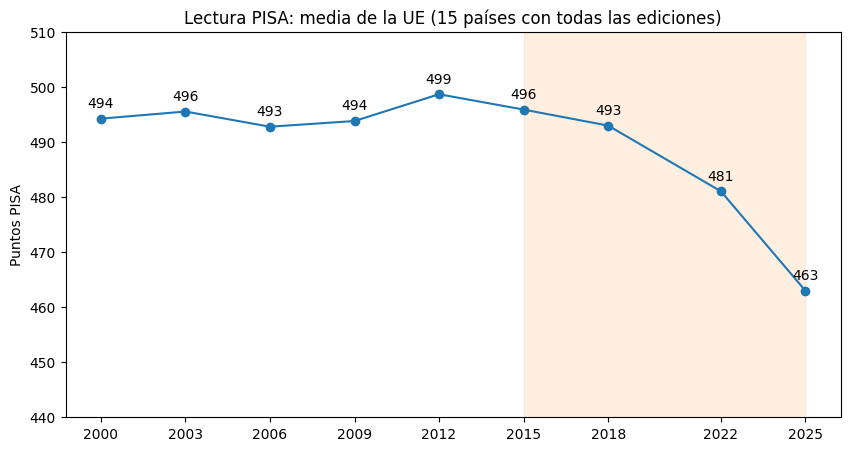

In [59]:
fig, ax = plt.subplots(figsize=(10, 5))  #generar marco del grafico
ax.plot(ue15.index, ue15.values, marker='o', color='tab:blue') #establecer eje X = index(año del estudio), y = valor de los datos
ax.axvspan(2015, 2025, color='tab:orange', alpha=0.12) #introducir franja naranja para destacar periodo del origen del smartphone  
for anio, nota in ue15.items():
    ax.annotate(f'{nota:.0f}', (anio, nota), textcoords='offset points', xytext=(0, 8), ha='center') #pintar la nota sobre cada punto
ax.set_ylim(440, 510) #establecer limite del eje y
ax.set_xticks(ue15.index) #dividir en cachitos el eje x.
ax.set_title('Lectura PISA: media de la UE (15 países con todas las ediciones)') #establecer title del grafico
ax.set_ylabel('Puntos PISA') #establecer title del eje y
plt.savefig('presentacion/img/02_lectura_ue.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show() #lanzar grafico

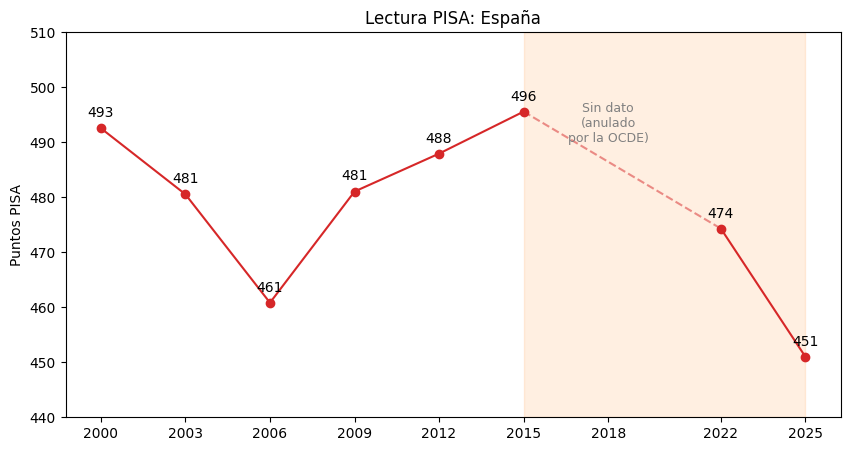

In [60]:
anios = [2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022, 2025]  
espana_completa = espanita_serie.reindex(anios)   #reindexar el dataset con años separado, se reintegra el index con estos nuevos valores

fig, ax = plt.subplots(figsize=(10, 5))  #crear cuadro
ax.plot(espana_completa.index, espana_completa.values, marker='o', color='tab:red')  #establecer x = indice del dataset (anios), y = valores del dataset
ax.plot([2015, 2022], [espanita_serie[2015], espanita_serie[2022]],
        linestyle='--', color='tab:red', alpha=0.5)  #dibujar linea con transparencia 0.5 para representar datos faltantes
ax.axvspan(2015, 2025, color='tab:orange', alpha=0.12)  #establecer franja naranja para representar caida acentuada
for anio, nota in espanita_serie.items():
    ax.annotate(f'{nota:.0f}', (anio, nota), textcoords='offset points', xytext=(0, 8), ha='center') #establecer anotaciones con los valores sobre cada punto
ax.text(2018, 490, 'Sin dato\n(anulado\npor la OCDE)', ha='center', fontsize=9, color='grey')  #comentario fijado para datos faltantes
ax.set_ylim(440, 510)
ax.set_xticks(anios)
ax.set_title('Lectura PISA: España')
ax.set_ylabel('Puntos PISA')
plt.savefig('presentacion/img/03_lectura_espana.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()  #limites, labels lanzar el grafico

,UE,España,Diferencia
Year,,,
2000,494.3,492.6,-1.7
2003,495.6,480.5,-15.1
2006,492.8,460.8,-32.0
2009,493.9,481.0,-12.8
2012,498.7,487.9,-10.8
2015,495.9,495.6,-0.4
2022,481.1,474.3,-6.8
2025,463.0,451.0,-12.0


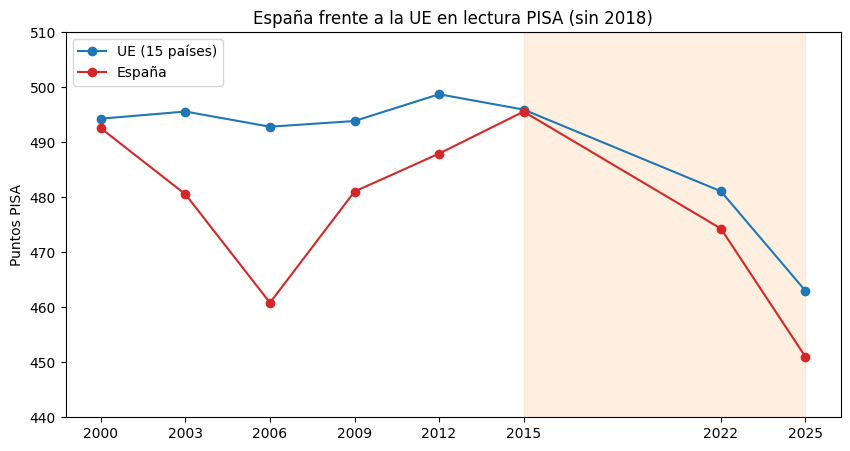

In [61]:
comparacion = pd.DataFrame({'UE': ue15, 'España': espana_completa}).dropna()   # el dropna quita 2018
comparacion['Diferencia'] = comparacion['España'] - comparacion['UE']    #Crear un diccionario con la comparacion entre valores de españita y UE
display(comparacion.round(1))

fig, ax = plt.subplots(figsize=(10, 5)) 
ax.plot(comparacion.index, comparacion['UE'], marker='o', label='UE (15 países)')
ax.plot(comparacion.index, comparacion['España'], marker='o', color='tab:red', label='España')  #representar valores de ambos datasets para comparacion grafica
ax.axvspan(2015, 2025, color='tab:orange', alpha=0.12) #zona naranja habitual para representar zona de caída
ax.set_ylim(440, 510)
ax.set_xticks(comparacion.index)
ax.set_title('España frente a la UE en lectura PISA (sin 2018)')
ax.set_ylabel('Puntos PISA')
ax.legend() #limites, labels y lanzar el gráfico
plt.savefig('presentacion/img/04_lectura_comparacion.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

In [62]:
pisa_maths_ue_25 = pd.DataFrame(pd.read_csv('data/PISA_2025_UE_matematicas.csv'))
pisa_maths = pd.DataFrame(pd.read_csv('data/matematics.csv'))
ue = ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark',
      'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Ireland',
      'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Poland',
      'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden']
pisa_maths_general = pd.concat([pisa_maths, pisa_maths_ue_25])

pisa_maths_general = pisa_maths_general[pisa_maths_general['Entity'].isin(ue)]

pisa_maths_general


,Entity,Code,Year,Mathematics
19,Austria,AUT,2003,505.61100
20,Austria,AUT,2006,505.48360
21,Austria,AUT,2009,495.90866
22,Austria,AUT,2012,505.54074
23,Austria,AUT,2015,496.74228
...,...,...,...,...
22,Romania,ROU,2025,419.00000
23,Slovakia,SVK,2025,469.00000
24,Slovenia,SVN,2025,460.00000
25,Spain,ESP,2025,457.00000


In [63]:
# 1. Media de la UE con los países que tienen todas las ediciones hasta 2022
ediciones_m = pisa_maths_general[pisa_maths_general['Year'] <= 2022].groupby('Entity')['Year'].count()
completos_m = ediciones_m[ediciones_m == ediciones_m.max()].index   # el máximo de ediciones, sin escribir el número a mano

ue_maths = (pisa_maths_general[pisa_maths_general['Entity'].isin(completos_m)]
            .groupby('Year')['Mathematics'].mean())

# 2. España como serie, con el año como índice
espanita_maths = (pisa_maths_general[pisa_maths_general['Entity'] == 'Spain']
                  .set_index('Year')['Mathematics'])

# 3. Juntas en una tabla, con la diferencia
comparacion_m = pd.DataFrame({'UE': ue_maths, 'España': espanita_maths})
comparacion_m['Diferencia'] = comparacion_m['España'] - comparacion_m['UE']
display(comparacion_m.round(1))
print(len(completos_m), 'países en la media de la UE')

,UE,España,Diferencia
Year,,,
2003,499.8,485.1,-14.7
2006,497.9,480.0,-18.0
2009,497.1,483.5,-13.6
2012,495.9,484.3,-11.5
2015,493.7,485.8,-7.9
2018,496.2,481.4,-14.8
2022,478.2,473.1,-5.0
2025,466.9,457.0,-9.9


18 países en la media de la UE


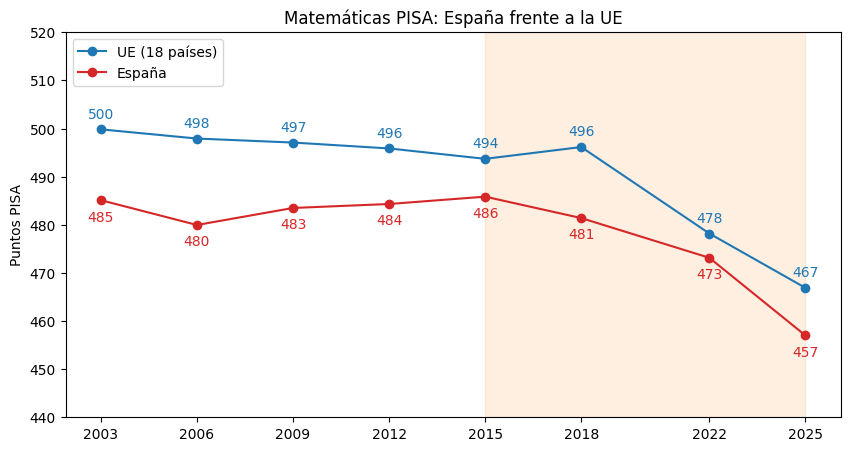

In [64]:

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(comparacion_m.index, comparacion_m['UE'], marker='o', label=f'UE ({len(completos_m)} países)')
ax.plot(comparacion_m.index, comparacion_m['España'], marker='o', color='tab:red', label='España')
ax.axvspan(2015, 2025, color='tab:orange', alpha=0.12)   # periodo de análisis
for anio, nota in comparacion_m['España'].items():
    ax.annotate(f'{nota:.0f}', (anio, nota), textcoords='offset points', xytext=(0, -15), ha='center', color='tab:red')
for anio, nota in comparacion_m['UE'].items():
    ax.annotate(f'{nota:.0f}', (anio, nota), textcoords='offset points', xytext=(0, 8), ha='center', color='tab:blue')
ax.set_ylim(440, 520)
ax.set_xticks(comparacion_m.index)
ax.set_title('Matemáticas PISA: España frente a la UE')
ax.set_ylabel('Puntos PISA')
ax.legend()

plt.savefig('presentacion/img/05_matematicas_comparacion.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

In [65]:
social_media = pd.DataFrame(pd.read_csv('data/social_media.csv', sep=';', decimal=',')) #cargar dataset social media para analisis
social_media = social_media.rename(columns={'Category' : 'Entity'}) #renombrar columna category a entity para encajar mejor en el merge con pisa
social_media['Total'] = (social_media['Boy'] + social_media['Girl']) / 2 #unir columnas chicos chicas en una media
social_media = social_media.drop(columns=['Boy','Girl'])
social_media['Entity'] = social_media['Entity'].replace({'Republic of Moldova': 'Moldova'}) #renombrar moldavia para encajar con informe pisa
media_uk = social_media[social_media['Entity'].isin(['England', 'Scotland', 'Wales'])]['Total'].mean() #sacar la media de los paises de uk
fila_uk = pd.DataFrame({'Entity': ['United Kingdom'], 'Total': [media_uk]})
fuera = ['England', 'Scotland', 'Wales', 'Luxembourg', 'Armenia']
redes = pd.concat([social_media[~social_media['Entity'].isin(fuera)], fila_uk], ignore_index=True) #eliminar paises que no estan en el informe pisa, e inglaterra para sustituir con la media de uk
pisa_data_new = pd.DataFrame(pd.read_csv('data/PISA.csv')) #reimportar dataset pisa limpio
pisa_2022 = pisa_data[pisa_data_new['Year'] == 2022][['Entity', 'Reading']] #sacar datos solo de 2022
redes_pisa = redes.merge(pisa_2022, on='Entity', how='inner') #merge de datos de redes con el informe pisa

redes_pisa

,Entity,Total,Reading
0,Romania,23.000000,428.49600
1,Ireland,19.000000,516.00995
2,Malta,18.500000,445.29883
3,Albania,17.500000,358.43475
4,Greece,15.500000,438.44060
5,Cyprus,14.000000,381.07570
6,Bulgaria,17.000000,404.30374
7,North Macedonia,15.000000,358.52213
8,Italy,13.500000,481.59827
9,Croatia,14.000000,475.49893


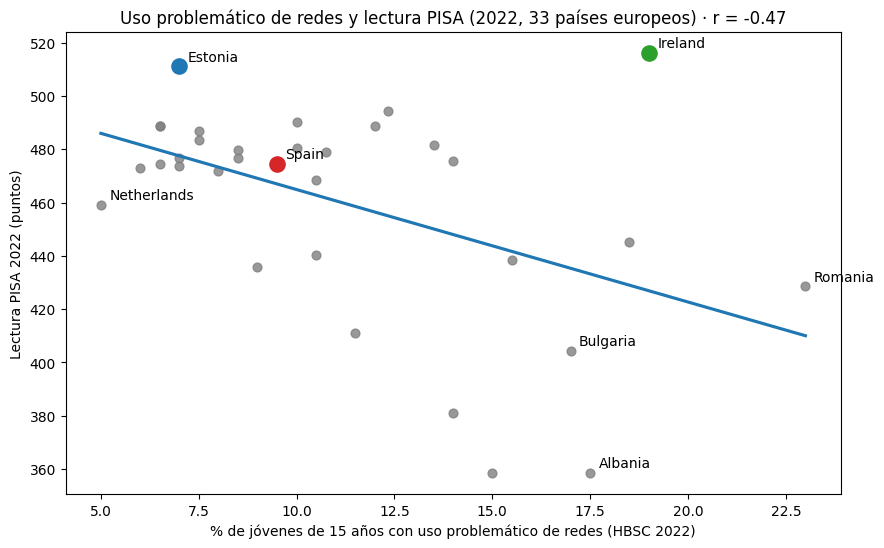

In [66]:


fig, ax = plt.subplots(figsize=(10, 6))


sns.regplot(data=redes_pisa, x='Total', y='Reading', ax=ax, ci=None,             #Establecer parámetros del gráfico, integrar data y formar linea y puntos
            scatter_kws={'color': 'grey', 's': 40}, line_kws={'color': 'tab:blue'})


espana = redes_pisa[redes_pisa['Entity'] == 'Spain']
ax.scatter(espana['Total'], espana['Reading'], color='tab:red', s=120, zorder=3)
ireland = redes_pisa[redes_pisa['Entity'] == 'Ireland']
ax.scatter(ireland['Total'], ireland['Reading'], color='tab:green', s=120, zorder=3)  #aislar españa, Irlanda, y Estonia sacando entity:  desde el dataset y destacar en el gráfico 
estonia = redes_pisa[redes_pisa['Entity'] == 'Estonia']
ax.scatter(estonia['Total'], estonia['Reading'], color='tab:blue', s=120, zorder=3)

destacados = ['Spain', 'Ireland', 'Romania', 'Albania', 'Bulgaria', 'Estonia', 'Netherlands']
for _, fila in redes_pisa[redes_pisa['Entity'].isin(destacados)].iterrows():                                 #sacar listado de paises destacados y recorrerlo con un for para posteriormente pintarlos en su posicion
    ax.annotate(fila['Entity'], (fila['Total'], fila['Reading']), textcoords='offset points', xytext=(6, 4))

r = redes_pisa['Total'].corr(redes_pisa['Reading'])                                                                            #correlacionar datos de uso de redes con lectura
ax.set_title(f'Uso problemático de redes y lectura PISA (2022, {len(redes_pisa)} países europeos) · r = {r:.2f}')
ax.set_xlabel('% de jóvenes de 15 años con uso problemático de redes (HBSC 2022)')
ax.set_ylabel('Lectura PISA 2022 (puntos)')
plt.savefig('presentacion/img/06_scatter_2022_lectura.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

In [67]:

pisa_maths_b = pd.DataFrame(pd.read_csv('data/matematics.csv'))
pisa_maths_22 = pisa_maths_b[pisa_maths_b['Year'] == 2022][['Entity', 'Mathematics']]
redes_pisa_maths = redes.merge(pisa_maths_22, on='Entity', how = 'inner')
set(redes['Entity']) - set(redes_pisa_maths['Entity'])   #asegurarse de que coincidan todos los paises por si alguno se llama diferente en los datasets
redes_pisa_maths


,Entity,Total,Mathematics
0,Romania,23.000000,427.76000
1,Ireland,19.000000,491.64830
2,Malta,18.500000,466.01610
3,Albania,17.500000,368.22170
4,Greece,15.500000,430.14633
5,Cyprus,14.000000,418.30667
6,Bulgaria,17.000000,417.30390
7,North Macedonia,15.000000,388.57550
8,Italy,13.500000,471.25946
9,Croatia,14.000000,463.10520


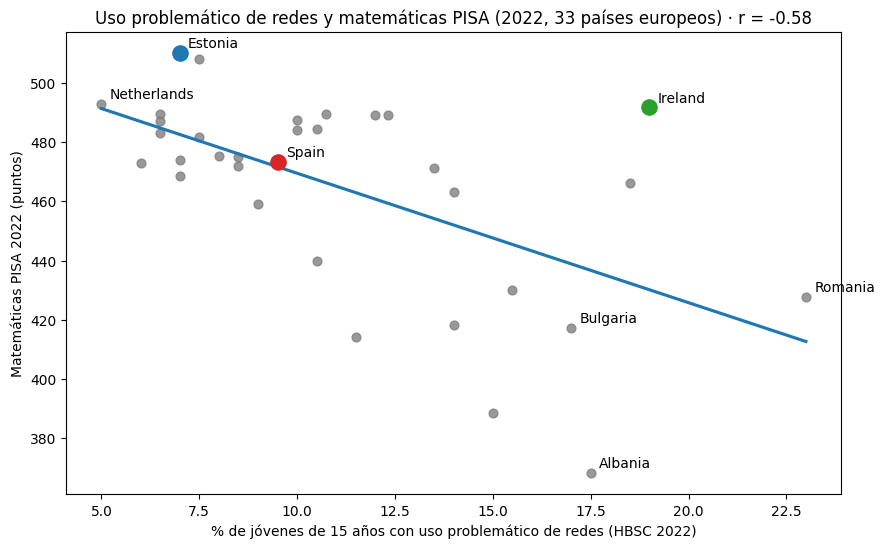

In [68]:
fig, ax = plt.subplots(figsize=(10, 6))


sns.regplot(data=redes_pisa_maths, x='Total', y='Mathematics', ax=ax, ci=None,             #Establecer parámetros del gráfico, integrar data y formar linea y puntos
            scatter_kws={'color': 'grey', 's': 40}, line_kws={'color': 'tab:blue'})


espana = redes_pisa_maths[redes_pisa_maths['Entity'] == 'Spain']
ax.scatter(espana['Total'], espana['Mathematics'], color='tab:red', s=120, zorder=3)
ireland = redes_pisa_maths[redes_pisa_maths['Entity'] == 'Ireland']
ax.scatter(ireland['Total'], ireland['Mathematics'], color='tab:green', s=120, zorder=3)  #aislar españa, Irlanda, y Estonia sacando entity:  desde el dataset y destacar en el gráfico 
estonia = redes_pisa_maths[redes_pisa_maths['Entity'] == 'Estonia']
ax.scatter(estonia['Total'], estonia['Mathematics'], color='tab:blue', s=120, zorder=3)

destacados = ['Spain', 'Ireland', 'Romania', 'Albania', 'Bulgaria', 'Estonia', 'Netherlands']
for _, fila in redes_pisa_maths[redes_pisa_maths['Entity'].isin(destacados)].iterrows():                                 #sacar listado de paises destacados y recorrerlo con un for para posteriormente pintarlos en su posicion
    ax.annotate(fila['Entity'], (fila['Total'], fila['Mathematics']), textcoords='offset points', xytext=(6, 4))

r = redes_pisa_maths['Total'].corr(redes_pisa_maths['Mathematics'])                                                                            #correlacionar datos de uso de redes con lectura
ax.set_title(f'Uso problemático de redes y matemáticas PISA (2022, {len(redes_pisa_maths)} países europeos) · r = {r:.2f}')
ax.set_xlabel('% de jóvenes de 15 años con uso problemático de redes (HBSC 2022)')
ax.set_ylabel('Matemáticas PISA 2022 (puntos)')
plt.savefig('presentacion/img/07_scatter_2022_matematicas.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

In [69]:
# --- PISA 2025: uso problemático de redes frente a lectura y matemáticas
pisa_25 = pd.read_csv('data/PISA_2025_europa.csv')

# Partimos de redes, pero recuperamos Luxemburgo, que en 2025 sí tiene datos de PISA
lux = social_media[social_media['Entity'] == 'Luxembourg']
redes_25 = pd.concat([redes, lux], ignore_index=True)

redes_pisa_25 = redes_25.merge(pisa_25[['Entity', 'Reading', 'Mathematics']], on='Entity', how='inner')

print(redes_pisa_25.shape)
redes_pisa_25[['Total', 'Reading', 'Mathematics']].corr().round(2)

(34, 4)


,Total,Reading,Mathematics
Total,1.00,-0.40,-0.52
Reading,-0.40,1.00,0.92
Mathematics,-0.52,0.92,1.00


In [80]:
import plotly.express as px

codigos = pisa_data[['Entity', 'Code']].drop_duplicates()     # códigos de país del PISA.csv
mapa_df = redes_pisa_25.merge(codigos, on='Entity', how='left')

mapa = px.choropleth(mapa_df, locations='Code', color='Total', hover_name='Entity',
                     hover_data={'Code': False, 'Reading': True, 'Mathematics': True},
                     color_continuous_scale='Reds', scope='europe',
                     labels={'Total': 'Uso problemático (%)', 'Reading': 'Lectura 2025',
                             'Mathematics': 'Matemáticas 2025'},
                     title='Uso problemático de redes en Europa (HBSC 2022)')
mapa.update_layout(
    paper_bgcolor='rgba(0,0,0,0)',     # fondo de toda la figura
    plot_bgcolor='rgba(0,0,0,0)',
    font_color='#F2EBEB',              # textos claros (leyenda, título) sobre fondo oscuro
    margin=dict(l=0, r=0, t=40, b=0),  # quita el margen blanco sobrante
)
mapa.update_geos(
    bgcolor='rgba(0,0,0,0)',           # fondo del propio mapa
    showframe=False,                   # quita el recuadro alrededor
    showocean=False,
    showlakes=False,
    landcolor='rgba(255,255,255,0.15)',  # países sin dato: gris translúcido
    coastlinecolor='#F2EBEB',
)
mapa.write_html('presentacion/graficas/mapa.html', include_plotlyjs='cdn')
mapa.show()

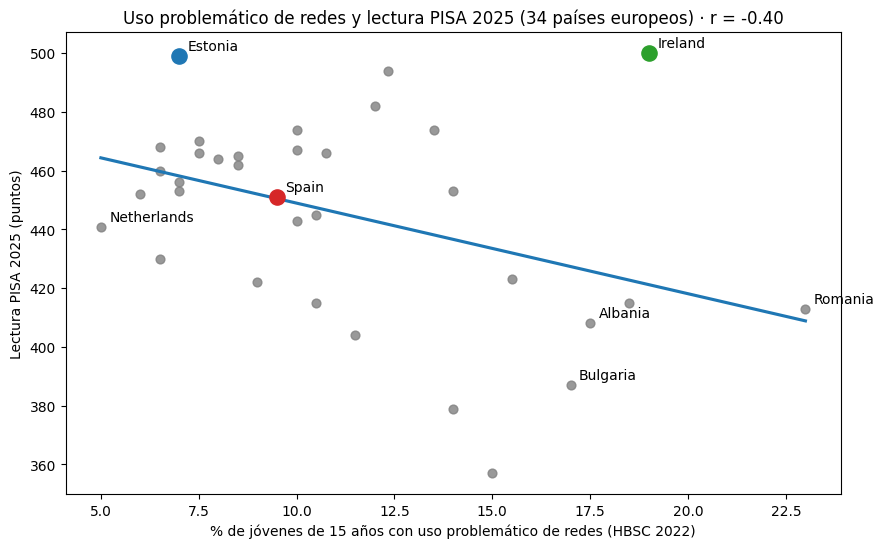

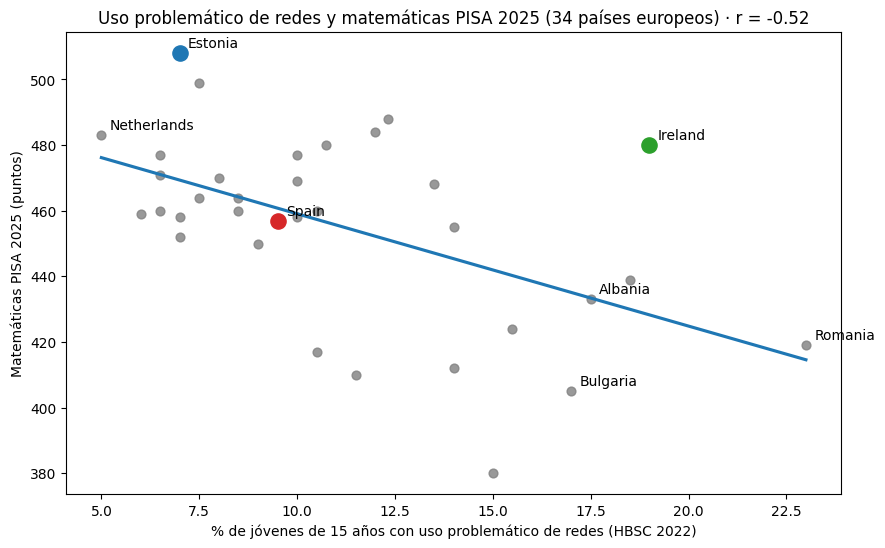

In [71]:
materias = {'Reading': 'Lectura', 'Mathematics': 'Matemáticas'}
colores = {'Spain': 'tab:red', 'Ireland': 'tab:green', 'Estonia': 'tab:blue'}
destacados = ['Spain', 'Ireland', 'Estonia', 'Romania', 'Albania', 'Bulgaria', 'Netherlands']

for columna, nombre in materias.items():        # una vuelta para lectura y otra para matemáticas
    fig, ax = plt.subplots(figsize=(10, 6))

    sns.regplot(data=redes_pisa_25, x='Total', y=columna, ax=ax, ci=None,
                scatter_kws={'color': 'grey', 's': 40}, line_kws={'color': 'tab:blue'})

    for pais, color in colores.items():             # países destacados con su color
        punto = redes_pisa_25[redes_pisa_25['Entity'] == pais]
        ax.scatter(punto['Total'], punto[columna], color=color, s=120, zorder=3)

    for _, fila in redes_pisa_25[redes_pisa_25['Entity'].isin(destacados)].iterrows():
        ax.annotate(fila['Entity'], (fila['Total'], fila[columna]),
                    textcoords='offset points', xytext=(6, 4))

    r = redes_pisa_25['Total'].corr(redes_pisa_25[columna])
    ax.set_title(f'Uso problemático de redes y {nombre.lower()} PISA 2025 '
                 f'({len(redes_pisa_25)} países europeos) · r = {r:.2f}')
    ax.set_xlabel('% de jóvenes de 15 años con uso problemático de redes (HBSC 2022)')
    ax.set_ylabel(f'{nombre} PISA 2025 (puntos)')
    plt.savefig(f'presentacion/img/08_scatter_2025_{columna}.png', dpi=200, bbox_inches='tight', transparent=True)
    plt.show()

,Lectura 2022,Lectura 2025,Matemáticas 2022,Matemáticas 2025
Grupo,,,,
Bajo uso,480.7,459.9,485.6,472.8
Uso medio,465.9,450.3,469.7,457.1
Alto uso,434.7,427.5,439.2,436.6


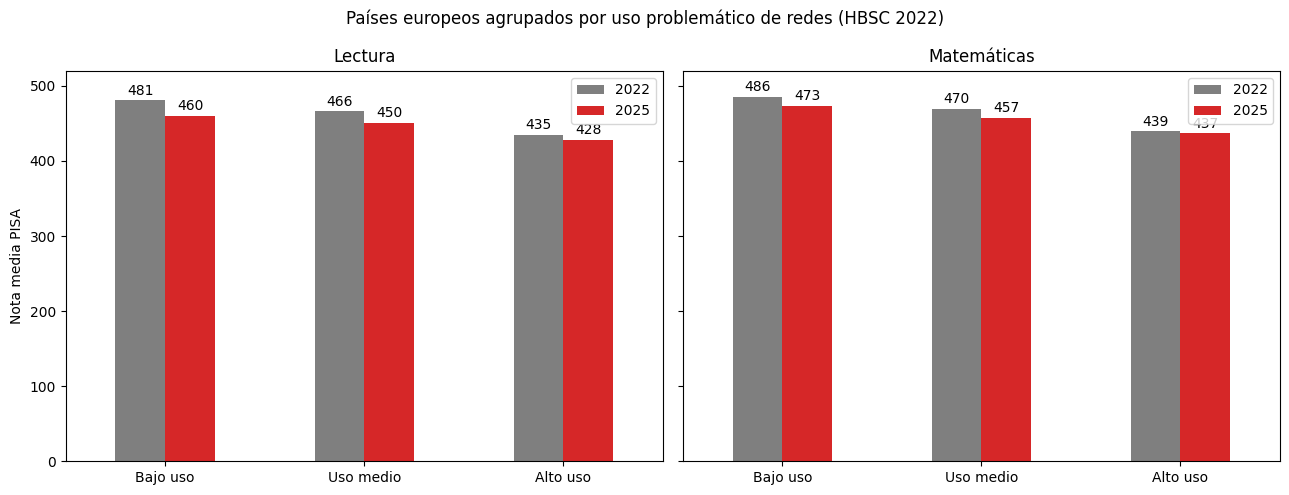

In [72]:
# 1. Una tabla con todo: uso de redes + notas 2022 y 2025 de las dos materias
evolucion = (redes
    .merge(pisa_2022.rename(columns={'Reading': 'Lectura 2022'}), on='Entity')
    .merge(pisa_maths_22.rename(columns={'Mathematics': 'Matemáticas 2022'}), on='Entity')
    .merge(pisa_25[['Entity', 'Reading', 'Mathematics']]
           .rename(columns={'Reading': 'Lectura 2025', 'Mathematics': 'Matemáticas 2025'}), on='Entity'))

# 2. Tres grupos del mismo tamaño según el uso problemático
evolucion['Grupo'] = pd.qcut(evolucion['Total'], 3, labels=['Bajo uso', 'Uso medio', 'Alto uso'])

# 3. Nota media de cada grupo
medias = evolucion.groupby('Grupo', observed=True)[
    ['Lectura 2022', 'Lectura 2025', 'Matemáticas 2022', 'Matemáticas 2025']].mean()
display(medias.round(1))

# 4. Las barras: un panel por materia
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, materia in zip(axes, ['Lectura', 'Matemáticas']):
    medias[[f'{materia} 2022', f'{materia} 2025']].plot(kind='bar', ax=ax,
                                                         color=['tab:grey', 'tab:red'], rot=0)
    for barras in ax.containers:
        ax.bar_label(barras, fmt='%.0f', padding=2)   # el número encima de cada barra
    ax.set_title(materia)
    ax.set_xlabel('')
    ax.set_ylim(0, 520)
    ax.legend(['2022', '2025'])
axes[0].set_ylabel('Nota media PISA')
fig.suptitle('Países europeos agrupados por uso problemático de redes (HBSC 2022)')
plt.tight_layout()
plt.savefig('presentacion/img/10_barras_grupos.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

In [73]:
hitos = pd.DataFrame({
    'Edición PISA': [2006, 2015, 2018, 2022, 2025],
    'Scroll y vídeo corto': [
        'Se inventa el scroll infinito',
        'Smartphone generalizado (feed algorítmico de Instagram en 2016)',
        'TikTok se lanza a nivel mundial',
        'Instagram Reels (2020) y YouTube Shorts (2021)',
        'Vídeo corto en todas las grandes redes'],
    'Denuncias y regulación': [
        '—', '—', '—',
        'Facebook Files (2021)',
        'DSA en vigor (2024); conclusiones preliminares de la UE contra TikTok y Meta, y veredicto de Los Ángeles (2026)'],
})

# Pegar a cada edición la nota de la UE-15 y la de España
hitos = hitos.merge(ue15.rename('Lectura UE-15'), left_on='Edición PISA', right_index=True, how='left')
hitos = hitos.merge(espanita_serie.rename('Lectura España'), left_on='Edición PISA', right_index=True, how='left')
hitos.round(1)

,Edición PISA,Scroll y vídeo corto,Denuncias y regulación,Lectura UE-15,Lectura España
0,2006,Se inventa el scroll infinito,—,492.8,460.8
1,2015,Smartphone generalizado (feed algorítmico de I...,—,495.9,495.6
2,2018,TikTok se lanza a nivel mundial,—,493.0,NaN
3,2022,Instagram Reels (2020) y YouTube Shorts (2021),Facebook Files (2021),481.1,474.3
4,2025,Vídeo corto en todas las grandes redes,DSA en vigor (2024); conclusiones preliminares...,463.0,451.0


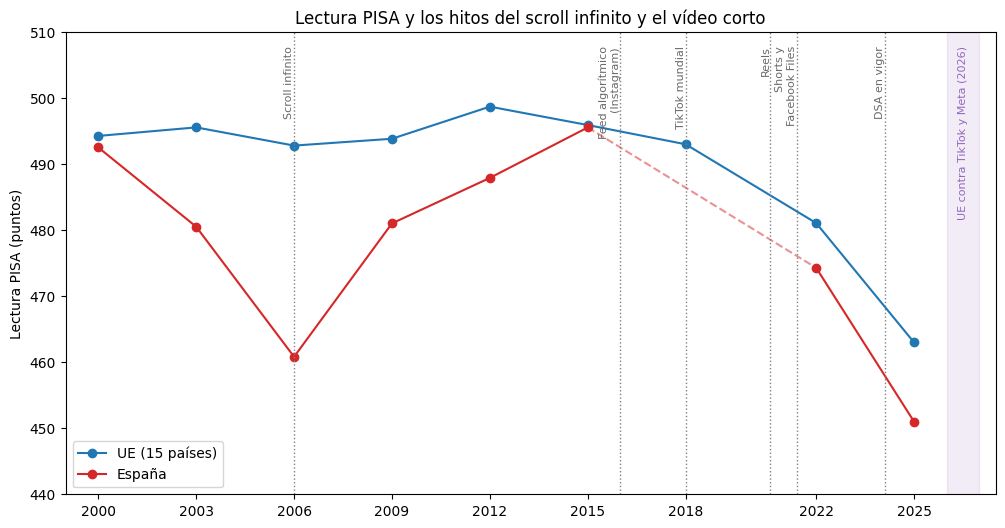

In [74]:
anios = [2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022, 2025]
espana_completa = espanita_serie.reindex(anios)

eventos = {2006: 'Scroll infinito',
           2016: 'Feed algorítmico\n(Instagram)',
           2018: 'TikTok mundial',
           2020.6: 'Reels',
           2021.4: 'Shorts y\nFacebook Files',
           2024.1: 'DSA en vigor'}

fig, ax = plt.subplots(figsize=(12, 6))

# Las dos series de lectura
ax.plot(ue15.index, ue15.values, marker='o', color='tab:blue', label='UE (15 países)')
ax.plot(espana_completa.index, espana_completa.values, marker='o', color='tab:red', label='España')
ax.plot([2015, 2022], [espanita_serie[2015], espanita_serie[2022]],
        linestyle='--', color='tab:red', alpha=0.5)   # España: sin dato en 2018

# Los hitos: línea vertical de puntos con su nombre en vertical
for anio, texto in eventos.items():
    ax.axvline(anio, color='grey', linestyle=':', linewidth=1)
    ax.text(anio, 508, texto, rotation=90, va='top', ha='right', fontsize=8, color='dimgrey')

# 2026: la UE contra TikTok y Meta, en franja morada después del último PISA
ax.axvspan(2026, 2027, color='tab:purple', alpha=0.12)
ax.text(2026.5, 508, 'UE contra TikTok y Meta (2026)', rotation=90, va='top', ha='center',
        fontsize=8, color='tab:purple')

ax.set_ylim(440, 510)
ax.set_xlim(1999, 2027.5)
ax.set_xticks(anios)
ax.set_ylabel('Lectura PISA (puntos)')
ax.set_title('Lectura PISA y los hitos del scroll infinito y el vídeo corto')
ax.legend(loc='lower left')
plt.savefig('presentacion/img/11_hitos.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

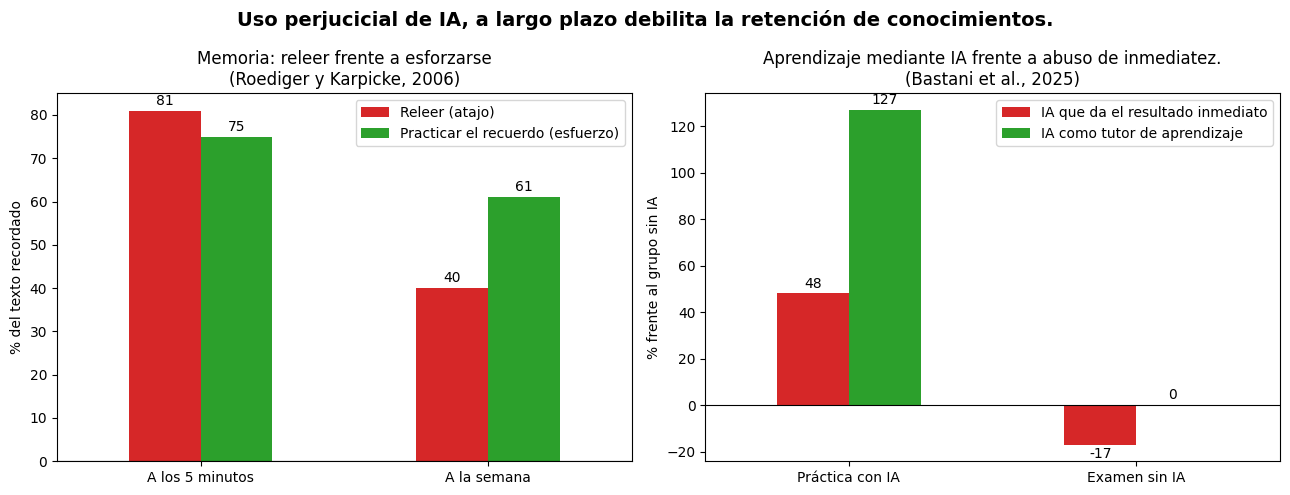

In [76]:
estudios = pd.read_csv('data/estudios_retencion.csv')
estudios['Grupo'] = estudios['Grupo'].replace({
    'IA que da respuestas (chuleta)': 'IA que da el resultado inmediato',
    'IA tutor (pistas)': 'IA como tutor de aprendizaje'})                                                                                                                     #cargar estudios desde el dataset, y separar en diccionarios
config = {
    'Roediger y Karpicke': {'momentos': ['A los 5 minutos', 'A la semana'],
                            'grupos': ['Releer (atajo)', 'Practicar el recuerdo (esfuerzo)'],
                            'titulo': 'Memoria: releer frente a esforzarse\n(Roediger y Karpicke, 2006)'},
    'Bastani et al.': {'momentos': ['Práctica con IA', 'Examen sin IA'],
                       'grupos': ['IA que da el resultado inmediato', 'IA como tutor de aprendizaje'],
                       'titulo': 'Aprendizaje mediante IA frente a abuso de inmediatez.\n(Bastani et al., 2025)'},
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (estudio, c) in zip(axes, config.items()):
    datos = estudios[estudios['Estudio'] == estudio]
    tabla = datos.pivot(index='Momento', columns='Grupo', values='Valor').loc[c['momentos'], c['grupos']]                   #crear nueva tabla desde los diccionarios
    tabla.plot(kind='bar', ax=ax, color=['tab:red', 'tab:green'], rot=0)
    for barras in ax.containers:
        ax.bar_label(barras, fmt='%.0f', padding=2)                                                                         #representar nuevos datos en el gráfico.
    ax.axhline(0, color='black', linewidth=0.8)   
    ax.set_title(c['titulo'])
    ax.set_xlabel('')
    ax.set_ylabel(datos['Unidad'].iloc[0])
    ax.legend(title='')
fig.suptitle('Uso perjucicial de IA, a largo plazo debilita la retención de conocimientos.', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('presentacion/img/12_estudios_ia.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

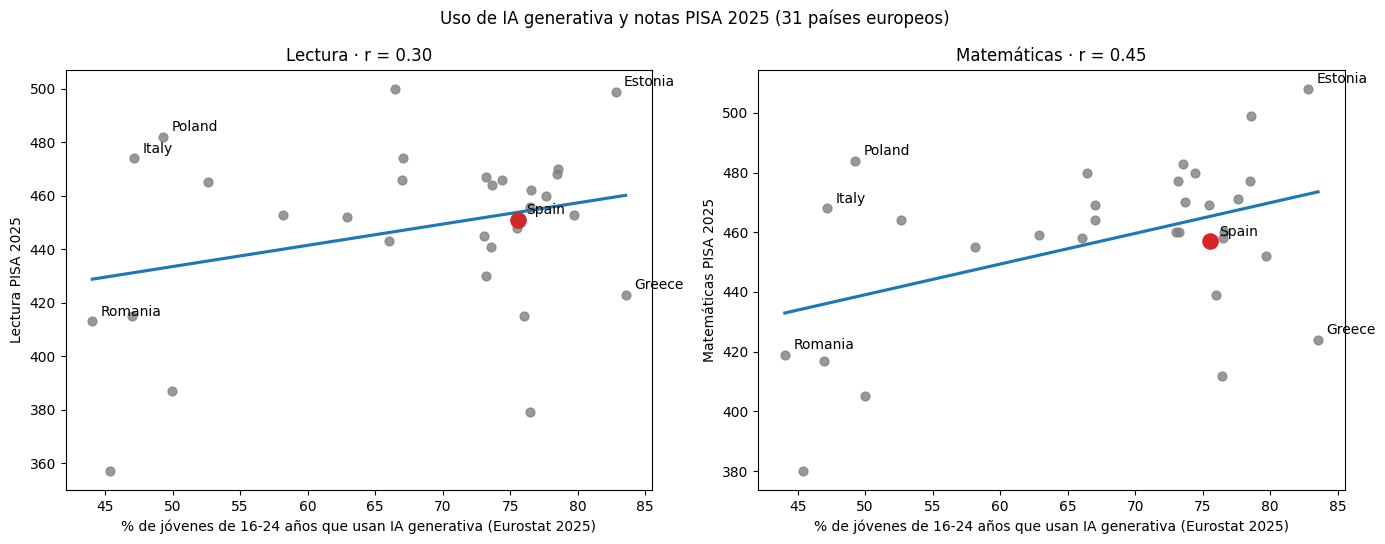

In [42]:
#Cruzar datos de anteriores sets con nuevas métricas de uso IA.

uso_ia = pd.read_csv('data/uso_ia.csv')
uso_ia = uso_ia.rename(columns={
    'Share of individuals aged 16-24 who used generative AI tools in the last three months': 'Uso_IA'})

ia_pisa = uso_ia[['Entity', 'Uso_IA']].merge(
    pisa_25[['Entity', 'Reading', 'Mathematics']], on='Entity', how='inner')      #mergear ambos datasets.

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)
for ax, (columna, nombre) in zip(axes, {'Reading': 'Lectura', 'Mathematics': 'Matemáticas'}.items()):
    sns.regplot(data=ia_pisa, x='Uso_IA', y=columna, ax=ax, ci=None,
                scatter_kws={'color': 'grey', 's': 40}, line_kws={'color': 'tab:blue'})
    espana = ia_pisa[ia_pisa['Entity'] == 'Spain']
    ax.scatter(espana['Uso_IA'], espana[columna], color='tab:red', s=120, zorder=3)
    for _, fila in ia_pisa[ia_pisa['Entity'].isin(['Spain', 'Estonia', 'Greece', 'Romania', 'Italy', 'Poland'])].iterrows():
        ax.annotate(fila['Entity'], (fila['Uso_IA'], fila[columna]), textcoords='offset points', xytext=(6, 4))
    r = ia_pisa['Uso_IA'].corr(ia_pisa[columna])
    ax.set_title(f'{nombre} · r = {r:.2f}')
    ax.set_xlabel('% de jóvenes de 16-24 años que usan IA generativa (Eurostat 2025)')
    ax.set_ylabel(f'{nombre} PISA 2025')
fig.suptitle(f'Uso de IA generativa y notas PISA 2025 ({len(ia_pisa)} países europeos)')
plt.tight_layout()
plt.savefig('presentacion/img/13_ia_pisa.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()